In [1]:
%pip install scikit-learn


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Question 1
# Load the dataset
tb_data = pd.read_csv(r'C:\Users\Hp\Desktop\INTRO TO DS ASSN 1\Tuberculosis_Dataset.csv')
print(f"Dataset successfully loaded! Dimensions: {tb_data.shape}")
tb_data.head()


Dataset successfully loaded! Dimensions: (400000, 22)


,Country,Year,TB_Incidence_Rate,Population,HIV_Prevalence,Treatment_Success_Rate,Mortality_Rate,Urban_Population_Percentage,Smoking_Rate,Alcohol_Consumption,...,Age_Group,Gender,HIV_CoInfection_Rate,BCG_Vaccination_Coverage,Multidrug_Resistance_Rate,Unemployment_Rate,GDP_Per_Capita,Life_Expectancy,TB_Screening_Coverage,Rural_Population_Percentage
0,Country_52,2003,56.145286,788566,15.124856,63.008939,18.417301,39.939777,38.323440,13.115522,...,25-54,Female,4.491676,87.163577,1.405499,27.964788,98235.258489,41.642988,53.486072,89.256182
1,Country_15,2021,137.470346,1282706,1.365238,63.861596,25.804928,78.360506,48.317584,13.676533,...,0-14,Female,0.527789,61.848695,4.022342,29.374837,35130.172901,63.968269,76.473413,42.549955
2,Country_61,2014,179.814220,1100374,13.770958,92.017009,15.319141,27.609710,9.085422,3.070677,...,65+,Female,0.977231,63.133755,14.618375,23.704493,24703.776975,81.883098,59.468310,29.938714
3,Country_21,2014,124.211205,1141641,8.198825,94.747900,9.405584,73.239525,39.927303,7.360397,...,65+,Male,3.218930,55.069057,5.758827,21.854778,16417.483760,64.295034,96.677854,32.578901
4,Country_24,2011,50.394259,759040,4.472235,83.710431,37.830973,11.821832,48.280581,4.958237,...,55-64,Female,1.938210,70.991237,0.201211,23.512661,60373.614322,52.874425,88.048894,17.109448


In [3]:
# Question 3
print("--- Structural Info ---")
tb_data.info()

print("\n--- Summary Statistics (Averages for the 22 Features) ---")
# Generate descriptive statistics and transpose (.T) for clean scanning
summary_stats = tb_data.describe(include='all').T

# Calculate the Median explicitly since describe() doesn't give a dedicated row label
summary_stats['median'] = tb_data.median(numeric_only=True)

# Filter down to look at essential public health averages side-by-side
summary_stats[['mean', 'median', 'std', 'min', 'max']]


--- Structural Info ---
<class 'pandas.DataFrame'>
RangeIndex: 400000 entries, 0 to 399999
Data columns (total 22 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Country                            400000 non-null  str    
 1   Year                               400000 non-null  int64  
 2   TB_Incidence_Rate                  400000 non-null  float64
 3   Population                         400000 non-null  int64  
 4   HIV_Prevalence                     400000 non-null  float64
 5   Treatment_Success_Rate             400000 non-null  float64
 6   Mortality_Rate                     400000 non-null  float64
 7   Urban_Population_Percentage        400000 non-null  float64
 8   Smoking_Rate                       400000 non-null  float64
 9   Alcohol_Consumption                400000 non-null  float64
 10  Healthcare_Expenditure_Per_Capita  400000 non-null  float64
 11  Primary_Healthcare_Access 

,mean,median,std,min,max
Country,NaN,NaN,NaN,NaN,NaN
Year,2010.990065,2.011000e+03,6.634506,2000.0,2022.0
TB_Incidence_Rate,150.014989,1.499920e+02,50.071879,0.0,383.098928
Population,1004924.271683,1.000864e+06,489029.137924,10000.0,3244383.0
HIV_Prevalence,9.987637,9.982016e+00,5.770656,0.000102,19.999983
Treatment_Success_Rate,80.001831,8.000594e+01,11.545157,60.00006,99.999936
Mortality_Rate,20.08506,2.000729e+01,9.788165,0.0,65.704344
Urban_Population_Percentage,50.014973,5.002226e+01,23.094261,10.000096,89.999993
Smoking_Rate,27.489608,2.748787e+01,12.982729,5.000037,49.999926
Alcohol_Consumption,7.503156,7.508720e+00,4.331976,0.000009,14.99999


In [4]:
# Question 4
print("--- Missing Values Report ---")

# Count absolute missing cells per column
missing_count = tb_data.isnull().sum()

#Calculate the corresponding percentage relative to the 400,000 records
missing_percentage = (tb_data.isnull().sum() / len(tb_data)) * 100

#Create a summary dataframe for assignment documentation
missing_report = pd.DataFrame({
    'Missing Count': missing_count,
    'Percentage (%)': missing_percentage
})

# Display the status of all 22 features
missing_report


--- Missing Values Report ---


,Missing Count,Percentage (%)
Country,0,0.0
Year,0,0.0
TB_Incidence_Rate,0,0.0
Population,0,0.0
HIV_Prevalence,0,0.0
Treatment_Success_Rate,0,0.0
Mortality_Rate,0,0.0
Urban_Population_Percentage,0,0.0
Smoking_Rate,0,0.0
Alcohol_Consumption,0,0.0


In [5]:
# Print all column names in the dataset to inspect their exact spelling
list(tb_data.columns)


['Country',
 'Year',
 'TB_Incidence_Rate',
 'Population',
 'HIV_Prevalence',
 'Treatment_Success_Rate',
 'Mortality_Rate',
 'Urban_Population_Percentage',
 'Smoking_Rate',
 'Alcohol_Consumption',
 'Healthcare_Expenditure_Per_Capita',
 'Primary_Healthcare_Access',
 'Age_Group',
 'Gender',
 'HIV_CoInfection_Rate',
 'BCG_Vaccination_Coverage',
 'Multidrug_Resistance_Rate',
 'Unemployment_Rate',
 'GDP_Per_Capita',
 'Life_Expectancy',
 'TB_Screening_Coverage',
 'Rural_Population_Percentage']

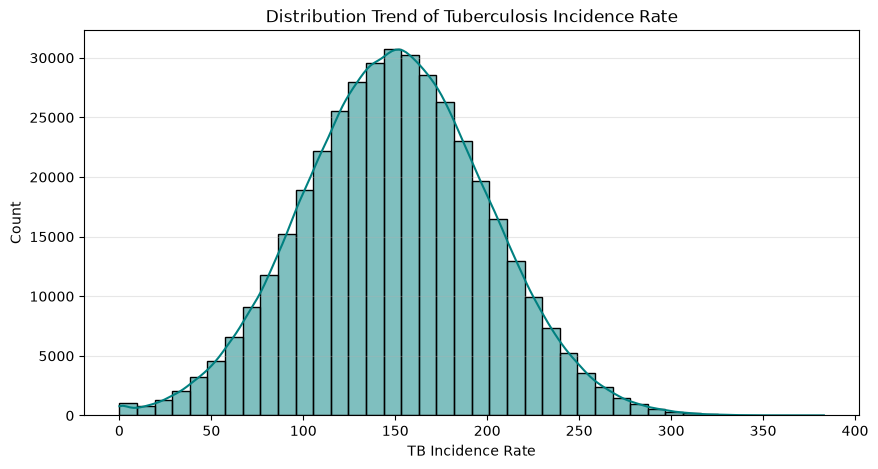

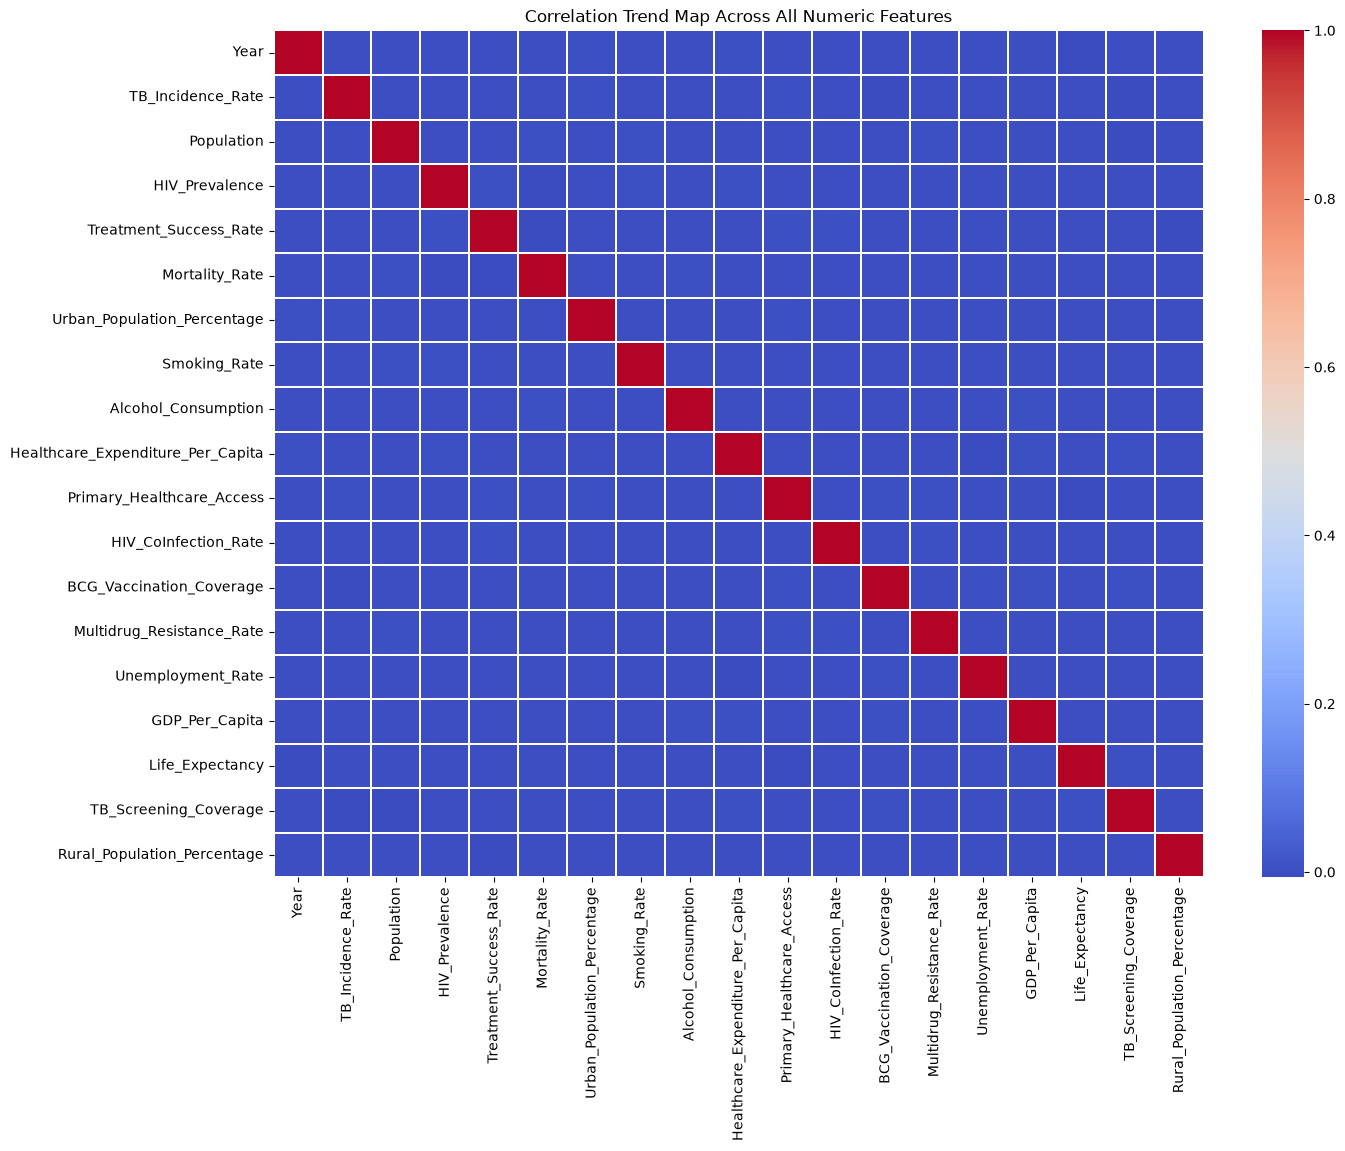

In [6]:
# Question 5
# 1. Target Variable Trend/Distribution Plot
plt.figure(figsize=(10, 5))
sns.histplot(tb_data['TB_Incidence_Rate'], kde=True, color='teal', bins=40)
plt.title('Distribution Trend of Tuberculosis Incidence Rate')
plt.xlabel('TB Incidence Rate')
plt.ylabel('Count')
plt.grid(axis='y', alpha=0.3)
plt.show()

# 2. Complete Feature Correlation Trend Map
plt.figure(figsize=(15, 11))
# Isolate numeric metrics out of your 22 variables
numeric_columns = tb_data.select_dtypes(include=['float64', 'int64'])
correlation_matrix = numeric_columns.corr()

# Draw the heatmap
sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', linewidths=0.3)
plt.title('Correlation Trend Map Across All Numeric Features')
plt.show()


In [7]:
# Question 6
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

print("--- Robust Data Preprocessing ---")

# Convert ALL non-numeric text features safely using universal One-Hot Encoding
processed_data = pd.get_dummies(tb_data, drop_first=True)

# Isolate predictors (X) and target variable (y)
X = processed_data.drop(columns=['TB_Incidence_Rate'])
y = processed_data['TB_Incidence_Rate']

# Split into Training (80%) and Testing (20%) datasets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Question 7
# Initialize and Train your Multiple Linear Regression Model
model = LinearRegression()
print("Training the regression model across rows...")
model.fit(X_train, y_train)
print("Model training completed successfully!")

# Generate test set predictions
y_pred = model.predict(X_test)
print("Predictions generated on test set!")


--- Robust Data Preprocessing ---
Training the regression model across rows...
Model training completed successfully!
Predictions generated on test set!


In [8]:
# Question 8
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Calculate the core evaluation metrics for your regression model
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# 2. Print the results cleanly for the assignment report
print("--- Model Performance Metrics ---")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R-squared Score (R2): {r2:.4f}")


--- Model Performance Metrics ---
Mean Absolute Error (MAE): 39.8396
Root Mean Squared Error (RMSE): 49.9103
R-squared Score (R2): -0.0001
